### Point Estimation

In [1]:
import numpy as np
from scipy.stats import norm

# Sample data
data = np.array([2.5, 3.1, 2.9, 3.8, 3.2])

# Method of Moments / MLE for Gaussian parameters
mu_hat = np.mean(data)
sigma2_hat = np.var(data, ddof=0) # ddof=0 for MLE, ddof=1 for unbiased estimator

# MLE optimization using scipy
mu_mle, std_mle = norm.fit(data)
print(f"MLE Mean: {mu_mle:.2f}, MLE Variance: {std_mle**2:.2f}")

MLE Mean: 3.10, MLE Variance: 0.18


### Hypothesis Testing

In [2]:
from scipy import stats

# Testing if the population mean equals a specific value (e.g., mu_0 = 3.0)
mu_0 = 3.0
t_stat, p_value = stats.ttest_1samp(data, popmean=mu_0)

alpha = 0.05 # 5% significance level
if p_value < alpha:
    print(f"Reject the null hypothesis (p-value: {p_value:.3f})")
else:
    print(f"Fail to reject the null hypothesis (p-value: {p_value:.3f})")

Fail to reject the null hypothesis (p-value: 0.662)


### Resampling Method - Jackknife method

In [3]:
# Jackknife for the sample mean
n = len(data)
jackknife_means = np.zeros(n)
for i in range(n):
    # Omit the i-th observation
    resample = np.delete(data, i)
    jackknife_means[i] = np.mean(resample)

jackknife_var = ((n - 1) / n) * np.sum((jackknife_means - np.mean(jackknife_means))**2)

# Bootstrap for the sample mean
n_iterations = 1000
bootstrap_means = np.zeros(n_iterations)
for i in range(n_iterations):
    # Resample with replacement
    resample = np.random.choice(data, size=n, replace=True)
    bootstrap_means[i] = np.mean(resample)

bootstrap_var = np.var(bootstrap_means)
print(f"Jackknife Variance: {jackknife_var:.4f}, Bootstrap Variance: {bootstrap_var:.4f}")

Jackknife Variance: 0.0450, Bootstrap Variance: 0.0363


### Model Selection - Goodness-to-Fit

In [4]:
# Calculating AIC and BIC for a Normal model fit
log_likelihood = np.sum(norm.logpdf(data, loc=mu_mle, scale=std_mle))
k = 2 # Number of parameters (mu, sigma)

aic = 2 * k - 2 * log_likelihood
bic = k * np.log(n) - 2 * log_likelihood

print(f"AIC: {aic:.2f}, BIC: {bic:.2f}")

AIC: 9.62, BIC: 8.83


### Bayesian Inference

In [5]:
# Simple Metropolis-Hastings MCMC for the mean of a Normal distribution (known variance)
prior_mu, prior_sigma = 3.0, 1.0 # Prior N(3, 1)
data_sigma = 0.5

def log_posterior(mu):
    log_prior = norm.logpdf(mu, loc=prior_mu, scale=prior_sigma)
    log_likelihood = np.sum(norm.logpdf(data, loc=mu, scale=data_sigma))
    return log_prior + log_likelihood

n_samples = 5000
chain = np.zeros(n_samples)
current_mu = prior_mu

for i in range(n_samples):
    proposal = np.random.normal(current_mu, 0.1)
    
    # Calculate acceptance probability
    p_accept = np.exp(log_posterior(proposal) - log_posterior(current_mu))
    
    if np.random.rand() < p_accept:
        current_mu = proposal
        
    chain[i] = current_mu

posterior_mean = np.mean(chain[1000:]) # Discard burn-in
print(f"Bayesian Posterior Mean (MCMC): {posterior_mean:.2f}")

Bayesian Posterior Mean (MCMC): 3.11


### Data Distributio vs Likelihood Fit

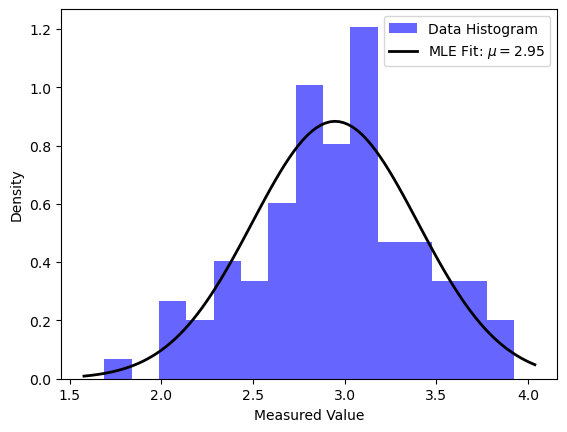

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# Simulated astronomical data
np.random.seed(42)
data = np.random.normal(loc=3.0, scale=0.5, size=100)

# Calculate MLE for mean and standard deviation
mu_mle, std_mle = norm.fit(data)

# Plotting
plt.hist(data, bins=15, density=True, alpha=0.6, color='b', label='Data Histogram')
xmin, xmax = plt.xlim()
x = np.linspace(xmin, xmax, 100)
p = norm.pdf(x, mu_mle, std_mle)
plt.plot(x, p, 'k', linewidth=2, label=f'MLE Fit: $\mu={mu_mle:.2f}$')
plt.xlabel('Measured Value')
plt.ylabel('Density')
plt.legend()
plt.show()

### Bootstrap Confidence Intervals

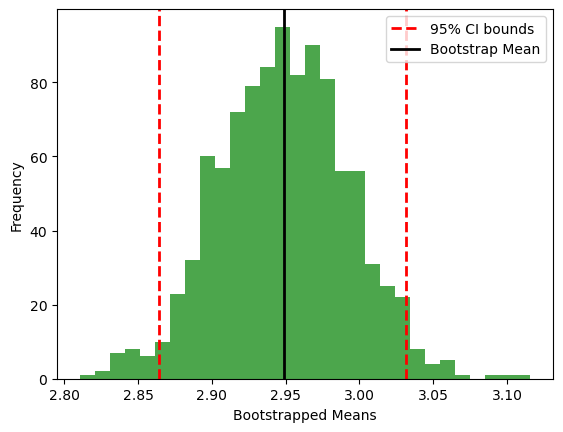

In [7]:
# Generate bootstrap samples for the mean
n_iterations = 1000
bootstrap_means = [np.mean(np.random.choice(data, size=len(data), replace=True)) for _ in range(n_iterations)]

# Calculate 95% confidence intervals
lower_bound, upper_bound = np.percentile(bootstrap_means, [2.5, 97.5])

# Plotting
plt.hist(bootstrap_means, bins=30, color='g', alpha=0.7)
plt.axvline(lower_bound, color='r', linestyle='dashed', linewidth=2, label='95% CI bounds')
plt.axvline(upper_bound, color='r', linestyle='dashed', linewidth=2)
plt.axvline(np.mean(bootstrap_means), color='k', linewidth=2, label='Bootstrap Mean')
plt.xlabel('Bootstrapped Means')
plt.ylabel('Frequency')
plt.legend()
plt.show()

### Bayesian Posterior Distribution (MCMC Trace and Density)

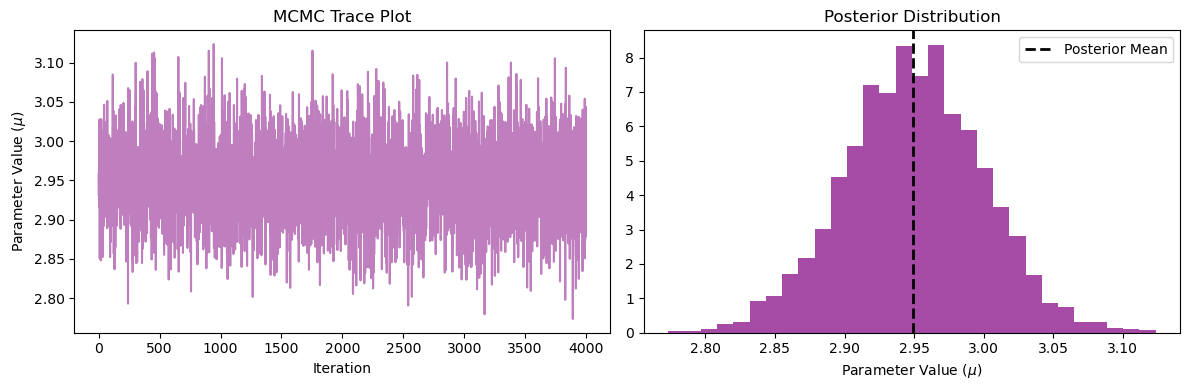

In [8]:
# Assuming 'chain' contains the accepted MCMC samples from the previous Bayesian example
# Mock MCMC chain data for visualization
chain = np.random.normal(loc=2.95, scale=0.05, size=4000) 

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# Trace Plot
ax1.plot(chain, alpha=0.5, color='purple')
ax1.set_title('MCMC Trace Plot')
ax1.set_xlabel('Iteration')
ax1.set_ylabel('Parameter Value ($\mu$)')

# Posterior Density Plot
ax2.hist(chain, bins=30, density=True, color='purple', alpha=0.7)
ax2.axvline(np.mean(chain), color='k', linestyle='dashed', linewidth=2, label='Posterior Mean')
ax2.set_title('Posterior Distribution')
ax2.set_xlabel('Parameter Value ($\mu$)')
ax2.legend()
plt.tight_layout()
plt.show()